# DAY 2 (part 1/2): Propagating orbits to the observation times
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 13 2026*

This is part 1 of 2. It propagates every observation to its observation time and writes `data/obs_elements_state_at_obstime.parquet`.

Part 2 (`propagate_orbit_2_geometry_H.ipynb`) reads that file and computes the distance from Earth, the phase angle and H. Restart the kernel before running part 2 to free the memory used here.

**Memory:** the parquet files have ~8M rows, so they are never loaded whole: we read only the rows of the test objects, or process the file in chunks.

# Propagating an orbit with `spiceypy.prop2b`

`state = spiceypy.prop2b(gm, pvinit, dt)` propagates a state vector under pure two-body (Keplerian) motion.

- `gm`: gravitational parameter of the central body (km³/s²)
- `pvinit`: initial state `[x, y, z, vx, vy, vz]` in km and km/s, relative to the central body
- `dt`: time to propagate, in seconds (can be negative to go backwards)
- returns: the state after `dt`, in the same frame and units

No kernels are needed: `prop2b` only uses the numbers you give it.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import spiceypy
import pyarrow.parquet as pq


## 1. Single propagation: a circular orbit at 1 AU around the Sun

In [21]:
gm_sun = 1.32712440018e11   # km^3/s^2
au = 1.495978707e8          # km

# Start on the +x axis, moving in +y at circular speed
v_circ = np.sqrt(gm_sun / au)
pvinit = np.array([au, 0.0, 0.0, 0.0, v_circ, 0.0])

# Propagate a quarter of a year
dt = 365.25 * 86400 / 4     # seconds
state = spiceypy.prop2b(gm_sun, pvinit, dt)

print("position (AU):", np.array(state[:3]) / au)   # should be ~[0, 1, 0]
print("velocity (km/s):", state[3:])                 # should be ~[-29.78, 0, 0]

position (AU): [2.96665647e-05 1.00000000e+00 0.00000000e+00]
velocity (km/s): [-2.97846918e+01  8.83609487e-04  0.00000000e+00]


In [22]:
def propagate_orbit(gm, state, dt):
    """Propagate a state vector under two-body motion with spiceypy.prop2b.

    Parameters
    ----------
    gm : float
        Gravitational parameter of the central body (km^3/s^2).
    state : array_like, shape (6,)
        Initial state [x, y, z, vx, vy, vz] in km and km/s.
    dt : float or array_like
        Time(s) to propagate, in seconds. Negative values propagate backwards.

    Returns
    -------
    numpy.ndarray
        Shape (6,) if dt is a scalar, or (len(dt), 6) if dt is an array.
    """
    state = np.ascontiguousarray(state, dtype=float)   # prop2b needs a contiguous array (not a strided view)
    if np.isscalar(dt):
        return np.array(spiceypy.prop2b(gm, state, dt))
    return np.array([spiceypy.prop2b(gm, state, t) for t in dt])

## 3. Propagating over many times to trace the orbit

Here an elliptical orbit: same start point but 20% faster than circular.

In [23]:
pvinit_ell = np.array([au, 0.0, 0.0, 0.0, 1.2 * v_circ, 0.0])

times = np.linspace(0, 3 * 365.25 * 86400, 1000)   # 3 years, in seconds
states = propagate_orbit(gm_sun, pvinit_ell, times)

x, y = states[:, 0] / au, states[:, 1] / au

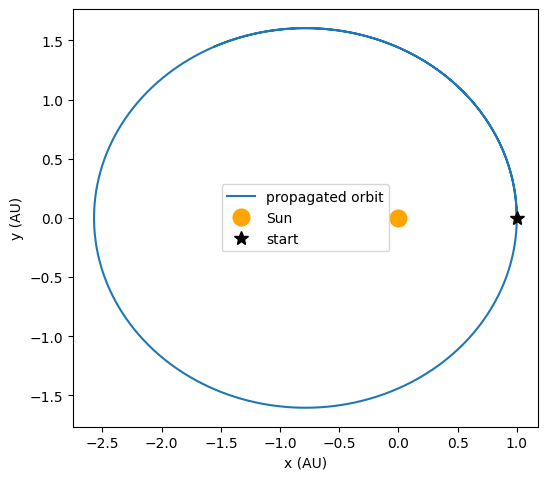

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, y, label="propagated orbit")
ax.plot(0, 0, "o", color="orange", markersize=12, label="Sun")
ax.plot(x[0], y[0], "k*", markersize=10, label="start")
ax.set_xlabel("x (AU)")
ax.set_ylabel("y (AU)")
ax.set_aspect("equal")
ax.legend()
plt.show()

## 4. Sanity check: energy should be conserved

In [25]:
r = np.linalg.norm(states[:, :3], axis=1)
v = np.linalg.norm(states[:, 3:], axis=1)
energy = 0.5 * v**2 - gm_sun / r
print("relative energy variation:", np.ptp(energy) / abs(energy[0]))

relative energy variation: 2.700336860444668e-14


## Let's get the orbit in each observation time for each object

In [26]:
import gc
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc

data_dir = 'data/'
obs_path = data_dir + 'obs_elements_state.parquet'

# The file is too big to load at once (MemoryError): look at its size and columns only
obs_file = pq.ParquetFile(obs_path)
print(f"{obs_file.metadata.num_rows:,} rows, {obs_file.metadata.num_row_groups} row groups")
print(obs_file.schema_arrow.names)


def load_objects(designations, path, columns=None, batch_size=200_000):
    """Rows of the given objects from a big parquet file, without loading the whole file.

    The file is read in batches of `batch_size` rows; only the matching rows of each batch are kept.
    """
    if columns is not None and 'mpc_designation' not in columns:
        columns = list(columns) + ['mpc_designation']
    pf = pq.ParquetFile(path)
    wanted = pa.array(list(designations), type=pa.string())
    parts = []
    for batch in pf.iter_batches(batch_size=batch_size, columns=columns):
        mask = pc.is_in(batch['mpc_designation'].cast(pa.string()), value_set=wanted)
        if pc.any(mask).as_py():
            parts.append(batch.filter(mask))
    if not parts:
        return pd.DataFrame(columns=columns)
    return pa.Table.from_batches(parts).to_pandas()


8,021,265 rows, 8 row groups
['obstime', 'permid', 'provid', 'mag', 'rmsmag', 'mpc_row', 'match_by', 'mpc_designation', 'n_provids', 'mpc_a', 'mpc_e', 'mpc_incl', 'mpc_node', 'mpc_peri', 'mpc_M', 'mpc_q', 'mpc_epoch_mjd', 'mpc_H', 'mpc_tp_jd', 'x', 'y', 'z', 'vx', 'vy', 'vz', 'epoch_et']


In [27]:
# First 30 rows only
next(obs_file.iter_batches(batch_size=30)).to_pandas()

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,n_provids,mpc_a,...,mpc_epoch_mjd,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et
0,2025-05-02 00:42:01.796,None,2025 MD8,23.096,0.124,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
1,2025-05-02 00:39:54.996,None,2025 MD8,22.927,0.127,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
2,2025-05-02 01:01:01.387,None,2025 MD8,23.055,0.105,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
3,2025-05-02 01:03:10.218,None,2025 MD8,23.059,0.129,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
4,2025-05-02 01:29:18.645,None,2025 MD8,22.911,0.072,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
5,2025-05-02 02:46:01.182,None,2025 MD8,23.957,0.171,1488086,provid,2025 MD8,1,2.814204,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
6,2025-05-02 02:41:08.571,None,2025 MP24,24.027,0.152,1488451,provid,2025 MP24,1,2.355546,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
7,2025-05-02 01:50:19.014,None,2025 MP24,22.737,0.065,1488451,provid,2025 MP24,1,2.355546,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
8,2025-05-02 01:52:26.255,None,2025 MP24,22.742,0.076,1488451,provid,2025 MP24,1,2.355546,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
9,2025-05-02 02:18:03.173,None,2025 MP24,23.609,0.116,1488451,provid,2025 MP24,1,2.355546,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0


In [28]:
# Only the rows of the two test objects (one pass over the file)
data_mpc = load_objects(['2021 LD56', '(162) Laurentia'], obs_path)

obj_test_1 = data_mpc[data_mpc['mpc_designation'] == '2021 LD56']
obj_test_1

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,n_provids,mpc_a,...,mpc_epoch_mjd,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et
0,2025-06-22 05:26:04.208,None,2021 LD56,22.376,0.0950,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
1,2025-07-02 03:51:36.254,None,2021 LD56,22.438,0.0434,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
2,2025-08-15 04:36:59.089,None,2021 LD56,22.320,0.0648,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
15,2025-08-17 06:40:44.029,None,2021 LD56,22.192,0.1421,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
16,2025-08-17 07:06:23.698,None,2021 LD56,22.579,0.1441,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
17,2025-08-17 07:07:40.808,None,2021 LD56,22.919,0.1932,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
18,2025-07-08 08:40:03.023,None,2021 LD56,22.123,0.1113,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
19,2025-07-08 09:29:20.847,None,2021 LD56,22.202,0.1242,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
20,2025-07-08 09:28:02.863,None,2021 LD56,22.081,0.1062,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
21,2025-07-08 02:08:09.807,None,2021 LD56,22.169,0.1698,1353730,provid,2021 LD56,1,40.233568,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0


### Propagate each observation from the MPC epoch to its observation time

The `x..vz` columns are the state at the MPC epoch (`epoch_et`). For each row we propagate by `dt = obs_et - epoch_et`.

In [29]:
# Leap seconds kernel (to convert UTC dates to ephemeris time) and the Sun's GM from DE440,
# the same GM used to build the state vectors at the MPC epoch
spiceypy.furnsh('kernels/naif0012.tls')
spiceypy.furnsh('kernels/gm_de440.tpc')
mu_sun = spiceypy.bodvrd('SUN', 'GM', 1)[1][0]   # km^3/s^2
AU_KM = 149597870.7                              # km

# Observation times as ephemeris time (seconds past J2000 TDB); Rubin obstime is UTC
obj_test_1 = obj_test_1.copy()
obj_test_1['obs_et'] = [spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in obj_test_1['obstime']]

# Time from the MPC epoch of the elements to each observation
obj_test_1['dt'] = obj_test_1['obs_et'] - obj_test_1['epoch_et']

# Propagate the state at the MPC epoch to each observation time
state_cols = ['x', 'y', 'z', 'vx', 'vy', 'vz']
obs_states = np.array([propagate_orbit(mu_sun, row[state_cols].to_numpy(dtype=float), row['dt'])
                       for _, row in obj_test_1.iterrows()])
for k, col in enumerate(state_cols):
    obj_test_1[col + '_obs'] = obs_states[:, k]

obj_test_1[['obstime', 'dt'] + [c + '_obs' for c in state_cols]]

,obstime,dt,x_obs,y_obs,z_obs,vx_obs,vy_obs,vz_obs
0,2025-06-22 05:26:04.208,-3.039317e+07,2.626008e+09,-5.172521e+09,2.184337e+08,4.165157,2.196945,1.224154
1,2025-07-02 03:51:36.254,-2.953483e+07,2.629582e+09,-5.170634e+09,2.194843e+08,4.163627,2.199957,1.224027
2,2025-08-15 04:36:59.089,-2.573051e+07,2.645409e+09,-5.162239e+09,2.241398e+08,4.156820,2.213291,1.223454
15,2025-08-17 06:40:44.029,-2.555029e+07,2.646158e+09,-5.161840e+09,2.243603e+08,4.156496,2.213923,1.223427
16,2025-08-17 07:06:23.698,-2.554875e+07,2.646165e+09,-5.161837e+09,2.243622e+08,4.156493,2.213928,1.223427
17,2025-08-17 07:07:40.808,-2.554867e+07,2.646165e+09,-5.161836e+09,2.243623e+08,4.156493,2.213928,1.223427
18,2025-07-08 08:40:03.023,-2.899913e+07,2.631812e+09,-5.169455e+09,2.201400e+08,4.162671,2.201836,1.223947
19,2025-07-08 09:29:20.847,-2.899617e+07,2.631825e+09,-5.169448e+09,2.201437e+08,4.162666,2.201846,1.223947
20,2025-07-08 09:28:02.863,-2.899625e+07,2.631824e+09,-5.169448e+09,2.201436e+08,4.162666,2.201846,1.223947
21,2025-07-08 02:08:09.807,-2.902264e+07,2.631714e+09,-5.169506e+09,2.201113e+08,4.162713,2.201753,1.223950


### Orbital elements at the observation time

`spiceypy.oscelt` converts each propagated state back to elements. In pure two-body motion only the mean anomaly $M$ changes; the other elements should match the MPC ones.

In [30]:
# oscelt returns [q, e, inc, node, peri, M, epoch, mu]: q in km, angles in radians
elts = np.array([spiceypy.oscelt(s, et, mu_sun)
                 for s, et in zip(obs_states, obj_test_1['obs_et'])])

obj_test_1['q_obs'] = elts[:, 0] / AU_KM
obj_test_1['e_obs'] = elts[:, 1]
obj_test_1['incl_obs'] = np.degrees(elts[:, 2])
obj_test_1['node_obs'] = np.degrees(elts[:, 3])
obj_test_1['peri_obs'] = np.degrees(elts[:, 4])
obj_test_1['M_obs'] = np.degrees(elts[:, 5])

obj_test_1[['obstime', 'mpc_q', 'q_obs', 'mpc_e', 'e_obs', 'mpc_incl', 'incl_obs',
            'mpc_node', 'node_obs', 'mpc_peri', 'peri_obs', 'mpc_M', 'M_obs']]

,obstime,mpc_q,q_obs,mpc_e,e_obs,mpc_incl,incl_obs,mpc_node,node_obs,mpc_peri,peri_obs,mpc_M,M_obs
0,2025-06-22 05:26:04.208,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.343776
1,2025-07-02 03:51:36.254,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.382143
2,2025-08-15 04:36:59.089,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.552196
15,2025-08-17 06:40:44.029,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560252
16,2025-08-17 07:06:23.698,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560321
17,2025-08-17 07:07:40.808,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560324
18,2025-07-08 08:40:03.023,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406089
19,2025-07-08 09:29:20.847,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406221
20,2025-07-08 09:28:02.863,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406218
21,2025-07-08 02:08:09.807,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.405038


## Compare with JPL Horizons: (162) Laurentia

We query JPL Horizons (`astroquery.jplhorizons`) for the osculating elements and state vector of a well-known main-belt asteroid, (162) Laurentia, at each Rubin observation time, and compare them with `propagate_orbit`.

- Horizons uses a full n-body integration (planets, large asteroids), while `prop2b` is pure two-body around the Sun, so the differences grow with the time from the MPC epoch.
- We ask Horizons for heliocentric (`500@10`) ecliptic J2000 values, the same frame as the MPC elements.
- We also query the MPC epoch itself: the difference there is between the MPC and JPL orbit solutions, before any propagation.

In [31]:
from astroquery.jplhorizons import Horizons

obj_test_2 = data_mpc[data_mpc['mpc_designation'] == '(162) Laurentia'].sort_values('obstime').copy()

# Observation times as ET; ET is TDB seconds past J2000 (JD 2451545.0 TDB), so JD_TDB follows directly
obj_test_2['obs_et'] = [spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in obj_test_2['obstime']]
epoch_et = obj_test_2['epoch_et'].iloc[0]          # MPC epoch of the elements (same for every row)
jd_obs = 2451545.0 + obj_test_2['obs_et'].to_numpy() / 86400
jd_epoch = 2451545.0 + epoch_et / 86400

# Horizons epochs are JD TDB; first epoch = MPC epoch, then the observation times
horizons = Horizons(id='162', id_type='smallbody', location='500@10',
                    epochs=[jd_epoch] + jd_obs.tolist())
hor_el = horizons.elements(refplane='ecliptic').to_pandas()
hor_vec = horizons.vectors(refplane='ecliptic').to_pandas()

# Horizons returns the epochs sorted in time, so we work with the times it returns.
# Propagate the MPC state to exactly those epochs
hor_et = (hor_el['datetime_jd'].to_numpy() - 2451545.0) * 86400
state0 = obj_test_2[state_cols].iloc[0].to_numpy(dtype=float)
prop_states = propagate_orbit(mu_sun, state0, hor_et - epoch_et)
prop_el = np.array([spiceypy.oscelt(s, et, mu_sun) for s, et in zip(prop_states, hor_et)])

In [32]:
def wrap180(angle):
    """Angle difference wrapped to [-180, 180) degrees."""
    return (angle + 180) % 360 - 180

AU_PER_DAY = AU_KM / 86400                    # km/s in one AU/day
r_hor = hor_vec[['x', 'y', 'z']].to_numpy() * AU_KM
v_hor = hor_vec[['vx', 'vy', 'vz']].to_numpy() * AU_PER_DAY

comparison = pd.DataFrame({
    'date (UTC)': np.where(np.isclose(hor_et, epoch_et, atol=1.0), 'MPC epoch',
                          [spiceypy.et2utc(et, 'ISOC', 0) for et in hor_et]),
    'days_from_epoch': (hor_et - epoch_et) / 86400,
    'dq [km]': (prop_el[:, 0] / AU_KM - hor_el['q']) * AU_KM,
    'de': prop_el[:, 1] - hor_el['e'],
    'dincl [arcsec]': wrap180(np.degrees(prop_el[:, 2]) - hor_el['incl']) * 3600,
    'dnode [arcsec]': wrap180(np.degrees(prop_el[:, 3]) - hor_el['Omega']) * 3600,
    'dperi [arcsec]': wrap180(np.degrees(prop_el[:, 4]) - hor_el['w']) * 3600,
    'dM [arcsec]': wrap180(np.degrees(prop_el[:, 5]) - hor_el['M']) * 3600,
    'dr [km]': np.linalg.norm(prop_states[:, :3] - r_hor, axis=1),
    'dv [m/s]': np.linalg.norm(prop_states[:, 3:] - v_hor, axis=1) * 1000,
})
comparison

,date (UTC),days_from_epoch,dq [km],de,dincl [arcsec],dnode [arcsec],dperi [arcsec],dM [arcsec],dr [km],dv [m/s]
0,2025-09-03T08:46:25,-278.633632,-226931.748659,2.638286e-04,3.621527,-18.267462,248.932484,-259.037971,34207.153244,2.754458
1,2025-09-03T08:47:05,-278.633172,-226931.251116,2.638280e-04,3.621521,-18.267406,248.932156,-259.037563,34207.044696,2.754453
2,2025-09-03T08:49:04,-278.631787,-226929.751951,2.638261e-04,3.621504,-18.267237,248.931171,-259.036333,34206.714565,2.754439
3,2025-09-03T08:49:44,-278.631328,-226929.254612,2.638254e-04,3.621498,-18.267180,248.930844,-259.035925,34206.605801,2.754434
4,2025-09-03T08:51:44,-278.629943,-226927.755511,2.638235e-04,3.621481,-18.267011,248.929858,-259.034695,34206.275685,2.754420
5,2025-09-03T08:55:03,-278.627639,-226925.261634,2.638204e-04,3.621452,-18.266729,248.928219,-259.032650,34205.727451,2.754396
6,2025-09-03T08:57:42,-278.625792,-226923.262554,2.638178e-04,3.621429,-18.266503,248.926904,-259.031010,34205.288556,2.754377
7,2025-11-17T02:10:13,-203.908773,-156439.868741,1.770733e-04,2.644906,-10.195417,188.667173,-186.547249,18807.502880,2.033517
8,2025-11-17T03:46:59,-203.841569,-156381.429655,1.770032e-04,2.644025,-10.189388,188.609867,-186.481413,18795.701625,2.032886
9,2025-11-17T03:50:33,-203.839091,-156379.274776,1.770006e-04,2.643993,-10.189166,188.607754,-186.478985,18795.266574,2.032863


In [33]:
# Side by side: propagated (prop) vs Horizons (hor) elements at the observation times
side_by_side = pd.DataFrame({
    'date (UTC)': comparison['date (UTC)'],
    'q prop [AU]': prop_el[:, 0] / AU_KM, 'q hor [AU]': hor_el['q'],
    'e prop': prop_el[:, 1], 'e hor': hor_el['e'],
    'incl prop': np.degrees(prop_el[:, 2]), 'incl hor': hor_el['incl'],
    'node prop': np.degrees(prop_el[:, 3]), 'node hor': hor_el['Omega'],
    'peri prop': np.degrees(prop_el[:, 4]), 'peri hor': hor_el['w'],
    'M prop': np.degrees(prop_el[:, 5]), 'M hor': hor_el['M'],
})
side_by_side

,date (UTC),q prop [AU],q hor [AU],e prop,e hor,incl prop,incl hor,node prop,node hor,peri prop,peri hor,M prop,M hor
0,2025-09-03T08:46:25,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515336,205.587291
1,2025-09-03T08:47:05,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515423,205.587378
2,2025-09-03T08:49:04,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515684,205.587638
3,2025-09-03T08:49:44,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.515770,205.587725
4,2025-09-03T08:51:44,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.516031,205.587985
5,2025-09-03T08:55:03,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.516465,205.588419
6,2025-09-03T08:57:42,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623504,205.516813,205.588766
7,2025-11-17T02:10:13,2.461634,2.462680,0.183172,0.182995,6.09272,6.091985,35.4191,35.421932,115.69265,115.640242,219.592989,219.644808
8,2025-11-17T03:46:59,2.461634,2.462679,0.183172,0.182995,6.09272,6.091986,35.4191,35.421930,115.69265,115.640258,219.605650,219.657451
9,2025-11-17T03:50:33,2.461634,2.462679,0.183172,0.182995,6.09272,6.091986,35.4191,35.421930,115.69265,115.640259,219.606117,219.657917


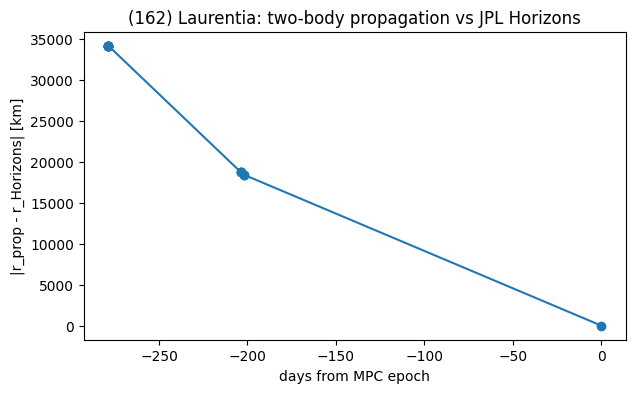

In [34]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(comparison['days_from_epoch'], comparison['dr [km]'], 'o-')
ax.set_xlabel('days from MPC epoch')
ax.set_ylabel('|r_prop - r_Horizons| [km]')
ax.set_title('(162) Laurentia: two-body propagation vs JPL Horizons')
plt.show()

In [35]:
# Position difference relative to the distance from the Sun (Horizons heliocentric distance)
sun_distance = pd.DataFrame({
    'date (UTC)': comparison['date (UTC)'],
    'days_from_epoch': comparison['days_from_epoch'],
    'r_sun [AU]': np.linalg.norm(r_hor, axis=1) / AU_KM,
    'dr [km]': comparison['dr [km]'],
})
sun_distance['dr / r_sun [%]'] = 100 * sun_distance['dr [km]'] / np.linalg.norm(r_hor, axis=1)
sun_distance

,date (UTC),days_from_epoch,r_sun [AU],dr [km],dr / r_sun [%]
0,2025-09-03T08:46:25,-278.633632,3.526801,34207.153244,0.006484
1,2025-09-03T08:47:05,-278.633172,3.526800,34207.044696,0.006483
2,2025-09-03T08:49:04,-278.631787,3.526800,34206.714565,0.006483
3,2025-09-03T08:49:44,-278.631328,3.526799,34206.605801,0.006483
4,2025-09-03T08:51:44,-278.629943,3.526799,34206.275685,0.006483
5,2025-09-03T08:55:03,-278.627639,3.526797,34205.727451,0.006483
6,2025-09-03T08:57:42,-278.625792,3.526796,34205.288556,0.006483
7,2025-11-17T02:10:13,-203.908773,3.472587,18807.502880,0.003620
8,2025-11-17T03:46:59,-203.841569,3.472528,18795.701625,0.003618
9,2025-11-17T03:50:33,-203.839091,3.472525,18795.266574,0.003618


**Reading the results**

- At the MPC epoch the two orbits agree to ~40 km: the MPC and JPL orbit solutions are essentially the same.
- Away from the epoch the difference grows (~18,000 km at 200 days, ~34,000 km at 280 days). This is not an error in `propagate_orbit`: it is the planetary perturbations (mostly Jupiter) that two-body motion ignores. They show up as a slow drift of the "constant" elements in Horizons (q, e, ω, Ω).

## Orbital elements at the observation time for every detection

For every observation in `data/obs_state_vector.parquet` we propagate the state at the MPC epoch to the observation time with `propagate_orbit` and convert it to osculating elements with `spiceypy.oscelt` (two-body, heliocentric ecliptic J2000). The results go to one file, `data/obs_elements_state_at_obstime.parquet`, with:

- identification columns: `obstime`, `mpc_row`, `mpc_designation`, `n_provids`, `obs_et`, `dt_from_epoch_days`
- osculating elements `a, e, q, incl, node, peri, M` [AU, deg]
- state vector `x, y, z, vx, vy, vz` [km, km/s]

- The file has ~8M rows, so it is processed in chunks: only the needed columns are read, and each chunk is written to the output file before the next one is read. This keeps memory low.
- The UTC → ET conversion is done with astropy (vectorized; it agrees with SPICE's `str2et` to ~10 µs).
- Takes a few minutes.

In [36]:
import time
import pyarrow as pa
import pyarrow.parquet as pq
from astropy.time import Time

def elements_at_obstime(chunk):
    """Propagate each row's MPC-epoch state to its observation time; return a DataFrame."""
    t_tdb = Time(chunk['obstime'].to_numpy(), scale='utc').tdb
    obs_et = (t_tdb.jd1 - 2451545.0) * 86400 + t_tdb.jd2 * 86400   # TDB seconds past J2000
    dt = obs_et - chunk['epoch_et'].to_numpy()
    states0 = chunk[state_cols].to_numpy(dtype=float)

    n = len(chunk)
    states = np.full((n, 6), np.nan)
    elts = np.full((n, 6), np.nan)            # q [km], e, inc, node, peri, M [rad]
    for k in range(n):
        try:
            states[k] = propagate_orbit(mu_sun, states0[k], dt[k])
            elts[k] = spiceypy.oscelt(states[k], obs_et[k], mu_sun)[:6]
        except spiceypy.utils.exceptions.SpiceyError:
            pass                              # leave NaN for this row

    q_au = elts[:, 0] / AU_KM
    e = elts[:, 1]
    return pd.DataFrame({
        'obstime': chunk['obstime'].to_numpy(),          # UTC
        'mpc_row': chunk['mpc_row'].array,
        'mpc_designation': chunk['mpc_designation'].array,
        'n_provids': chunk['n_provids'].array,
        'obs_et': obs_et,
        'dt_from_epoch_days': dt / 86400,
        # Heliocentric ecliptic J2000 state at the observation time [km, km/s]
        'x': states[:, 0], 'y': states[:, 1], 'z': states[:, 2],
        'vx': states[:, 3], 'vy': states[:, 4], 'vz': states[:, 5],
        # Osculating two-body elements at the observation time [AU, deg]
        'a': np.where(e < 1, q_au / (1 - e), np.nan),
        'e': e,
        'q': q_au,
        'incl': np.degrees(elts[:, 2]),
        'node': np.degrees(elts[:, 3]),
        'peri': np.degrees(elts[:, 4]),
        'M': np.degrees(elts[:, 5]),
    })

In [37]:
from parquet_docs import describe

in_path = data_dir + 'obs_elements_state.parquet'
out_elements_states = data_dir + 'obs_elements_state_at_obstime.parquet'
columns = ['obstime', 'mpc_row', 'mpc_designation', 'n_provids', 'epoch_et'] + state_cols

id_cols = ['obstime', 'mpc_row', 'mpc_designation', 'n_provids', 'obs_et', 'dt_from_epoch_days']
element_cols = ['a', 'e', 'q', 'incl', 'node', 'peri', 'M']

source = pq.ParquetFile(in_path)
n_rows = source.metadata.num_rows
writer = None
done = 0
start = time.time()
for batch in source.iter_batches(batch_size=500_000, columns=columns):
    result = elements_at_obstime(batch.to_pandas())
    # Elements and state vector in the same file
    table = pa.Table.from_pandas(result[id_cols + element_cols + state_cols], preserve_index=False)
    table = describe(table, out_elements_states)     # description of each column, saved in the file
    if writer is None:
        writer = pq.ParquetWriter(out_elements_states, table.schema)
    writer.write_table(table)
    done += len(result)
    print(f'{done:,} / {n_rows:,} rows  ({time.time() - start:.0f} s)')
writer.close()
del result, table
gc.collect()

500,000 / 8,021,265 rows  (18 s)
1,000,000 / 8,021,265 rows  (34 s)
1,500,000 / 8,021,265 rows  (50 s)
2,000,000 / 8,021,265 rows  (66 s)
2,500,000 / 8,021,265 rows  (82 s)
3,000,000 / 8,021,265 rows  (99 s)
3,500,000 / 8,021,265 rows  (115 s)
4,000,000 / 8,021,265 rows  (131 s)
4,500,000 / 8,021,265 rows  (148 s)
5,000,000 / 8,021,265 rows  (164 s)
5,500,000 / 8,021,265 rows  (180 s)
6,000,000 / 8,021,265 rows  (196 s)
6,500,000 / 8,021,265 rows  (212 s)
7,000,000 / 8,021,265 rows  (228 s)
7,500,000 / 8,021,265 rows  (244 s)
8,000,000 / 8,021,265 rows  (260 s)
8,021,265 / 8,021,265 rows  (260 s)


7275

In [38]:
# The file is ~8M rows: check it without loading everything into memory
elements_states_file = pq.ParquetFile(out_elements_states)
e_col = elements_states_file.read(columns=['e'])['e'].to_numpy()
print(f"{elements_states_file.metadata.num_rows:,} rows in {out_elements_states}, {np.isnan(e_col).sum()} failed propagations")

# Load one object, or a subset of columns, with filters / columns:
# pd.read_parquet(out_elements_states, filters=[('mpc_designation', '==', '(162) Laurentia')])
elements_states_file.read_row_group(0).slice(0, 5).to_pandas()

8,021,265 rows in data/obs_elements_state_at_obstime.parquet, 0 failed propagations


,obstime,mpc_row,mpc_designation,n_provids,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,x,y,z,vx,vy,vz
0,2025-05-02 00:42:01.796,1488086,2025 MD8,1,7.994186e+08,-402.970012,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.353219,-4.154336e+08,-1.213739e+08,3.257417e+07,2.903886,-16.963026,0.365492
1,2025-05-02 00:39:54.996,1488086,2025 MD8,1,7.994185e+08,-402.971479,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.352912,-4.154340e+08,-1.213718e+08,3.257412e+07,2.903801,-16.963051,0.365498
2,2025-05-02 01:01:01.387,1488086,2025 MD8,1,7.994197e+08,-402.956822,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.355973,-4.154303e+08,-1.213932e+08,3.257459e+07,2.904655,-16.962802,0.365431
3,2025-05-02 01:03:10.218,1488086,2025 MD8,1,7.994199e+08,-402.955331,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.356284,-4.154300e+08,-1.213954e+08,3.257463e+07,2.904742,-16.962776,0.365425
4,2025-05-02 01:29:18.645,1488086,2025 MD8,1,7.994214e+08,-402.937178,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.360074,-4.154254e+08,-1.214220e+08,3.257521e+07,2.905799,-16.962467,0.365342


**Next:** restart the kernel and continue with `propagate_orbit_2_geometry_H.ipynb`.